# Notebook 03 | K-Means Customer Segmentation
**Global Superstore – Customer Segmentation & Behavioral Analytics**

**Goal:** build a data-driven segmentation with K-Means and compare it with the rule-based RFM segments from SQL.

**Workflow**
1. Select behavioral features and remove redundant ones (correlation)
2. Fix skewness (log transform) and scale the features
3. Choose the number of clusters (elbow + silhouette)
4. Fit the final model and profile the clusters (original-scale values)
5. Compare clusters with the SQL RFM segments
6. Summarise in a small dashboard

| | |
|---|---|
| **Input** | `customer_features.csv` (from notebook 01) and the SQL view `customer_rfm_segments` |
| **Note** | Customer IDs are never used as features. Neither the clusters nor the SQL segments are treated as "ground truth". |

## Setup

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [ ]:
customer_df = pd.read_csv("customer_features.csv")
print("Dataset shape:", customer_df.shape)

customer_df.info()

Dataset shape: (4873, 20)
<class 'pandas.DataFrame'>
RangeIndex: 4873 entries, 0 to 4872
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              4873 non-null   str    
 1   total_orders             4873 non-null   int64  
 2   total_sales              4873 non-null   float64
 3   total_profit             4873 non-null   float64
 4   total_quantities         4873 non-null   int64  
 5   avg_items_per_order      4873 non-null   float64
 6   avg_order_value          4873 non-null   float64
 7   avg_profit_per_order     4873 non-null   float64
 8   first_purchase_date      4873 non-null   str    
 9   last_purchase_date       4873 non-null   str    
 10  active_months            4873 non-null   int64  
 11  avg_discount             4873 non-null   float64
 12  profit_margin            4873 non-null   float64
 13  unique_products          4873 non-null   int64  
 14  unique_ca

## 1. Feature selection
Start from ten candidate behavioral features and check how strongly they overlap. Two features that move together carry the same information, and K-Means would count it twice.

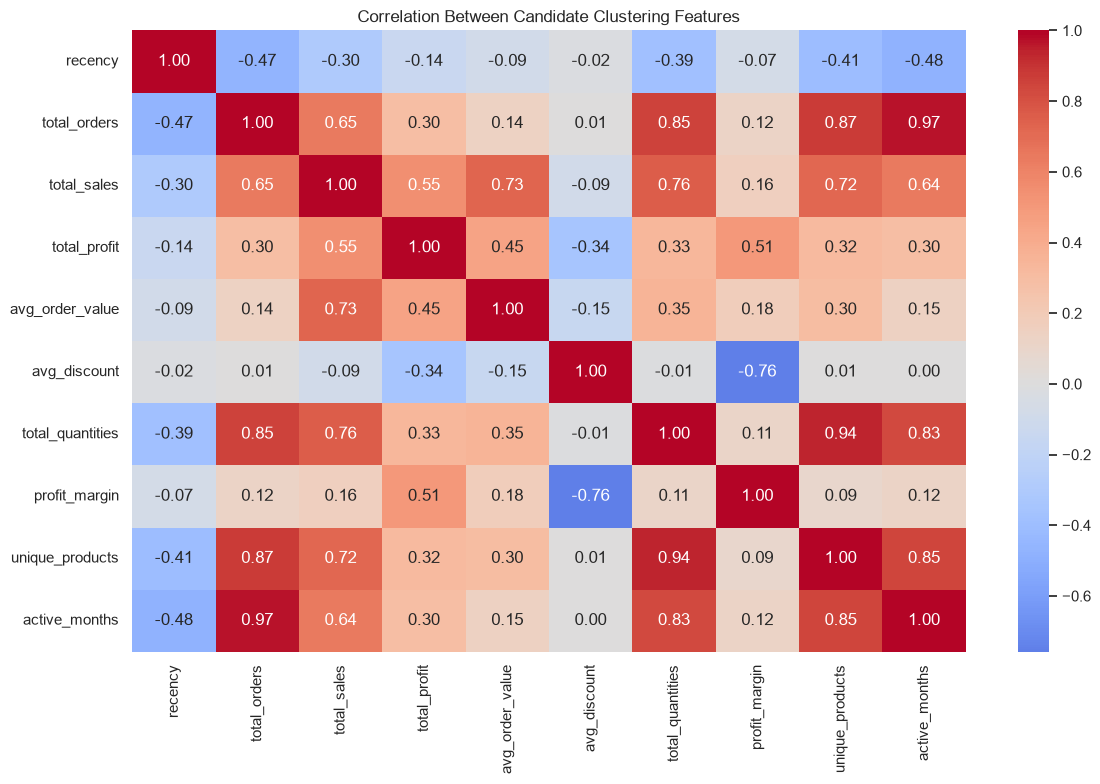

In [ ]:
candidate_features = [
    "recency",
    "total_orders",
    "total_sales",
    "total_profit",
    "avg_order_value",
    "avg_discount",
    "total_quantities",
    "profit_margin",
    "unique_products",
    "active_months"
]

correlation_matrix = customer_df[candidate_features].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Candidate Clustering Features")
plt.tight_layout()
plt.show()

Closer look at the groups of related features:

In [ ]:
customer_df[
    ["total_orders", "profit_margin", "active_months",
     "total_quantities", "unique_products"]
].corr()

,total_orders,profit_margin,active_months,total_quantities,unique_products
total_orders,1.000000,0.116578,0.972202,0.853844,0.870571
profit_margin,0.116578,1.000000,0.121349,0.110416,0.091916
active_months,0.972202,0.121349,1.000000,0.828641,0.846430
total_quantities,0.853844,0.110416,0.828641,1.000000,0.943951
unique_products,0.870571,0.091916,0.846430,0.943951,1.000000


In [ ]:
customer_df[
    ["total_sales", "total_profit", "avg_order_value", "avg_discount", "profit_margin"]
].corr()

,total_sales,total_profit,avg_order_value,avg_discount,profit_margin
total_sales,1.000000,0.552226,0.731155,-0.086022,0.156912
total_profit,0.552226,1.000000,0.448591,-0.340336,0.505509
avg_order_value,0.731155,0.448591,1.000000,-0.150253,0.176660
avg_discount,-0.086022,-0.340336,-0.150253,1.000000,-0.758070
profit_margin,0.156912,0.505509,0.176660,-0.758070,1.000000


**Decision:** drop `active_months`, `total_quantities` and `profit_margin` because they largely duplicate other features (for example, `active_months` is almost perfectly correlated with `total_orders`, and margin is largely a function of discount and profit). Keep seven features:
`recency`, `total_orders`, `total_sales`, `total_profit`, `avg_order_value`, `avg_discount`, `unique_products`.

## 2. Skewness and transformation
K-Means uses distances, so long right tails would dominate. Check skewness first.

In [ ]:
#investigating through skewness

selected_features = [
    "recency",
    "total_orders",
    "total_sales",
    "total_profit",
    "avg_order_value",
    "avg_discount",
    "unique_products"
]

skewness = customer_df[selected_features].skew().sort_values(
    ascending=False
)

skewness

avg_order_value    2.836586
recency            2.126019
total_sales        1.688757
avg_discount       1.472312
total_profit       1.159391
unique_products    0.800579
total_orders       0.529275
dtype: float64

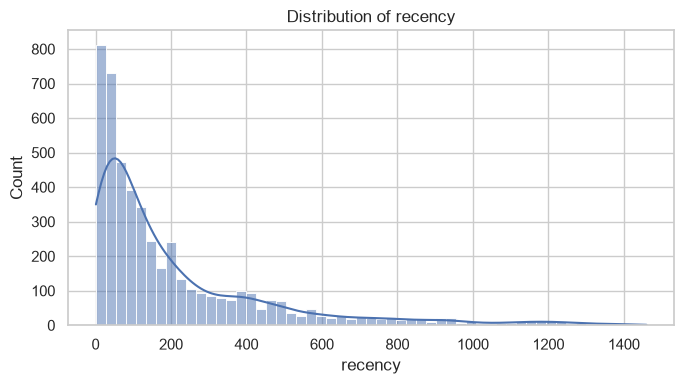

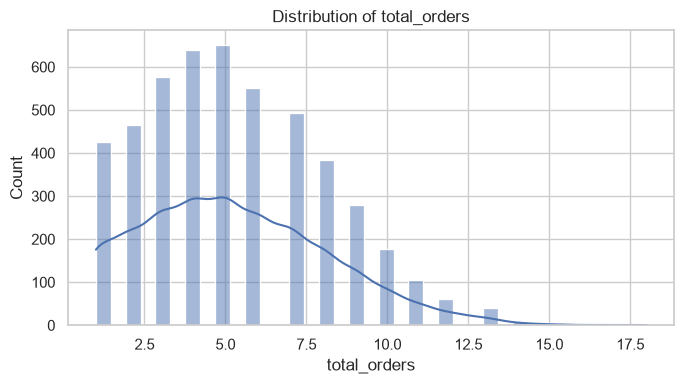

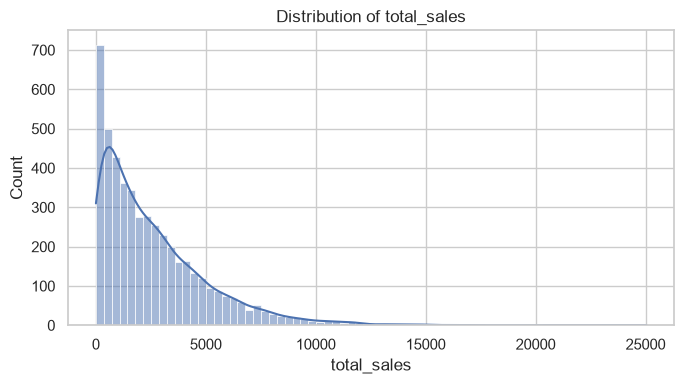

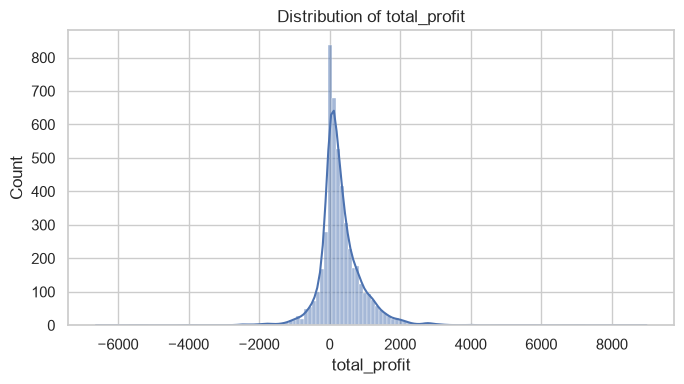

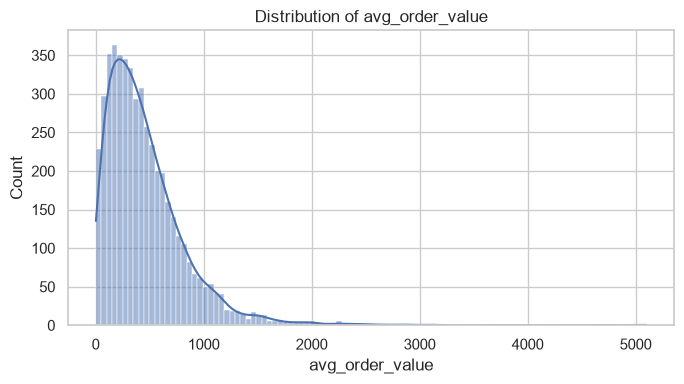

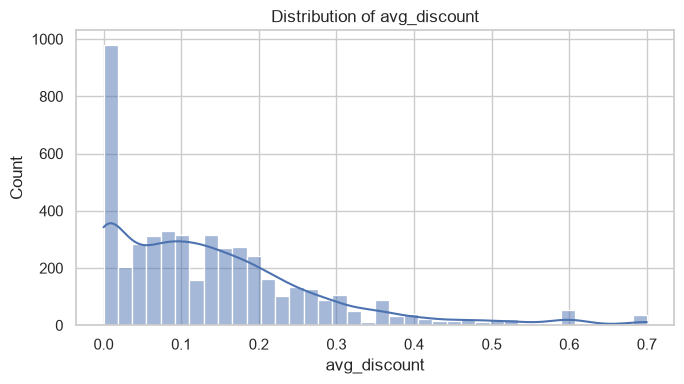

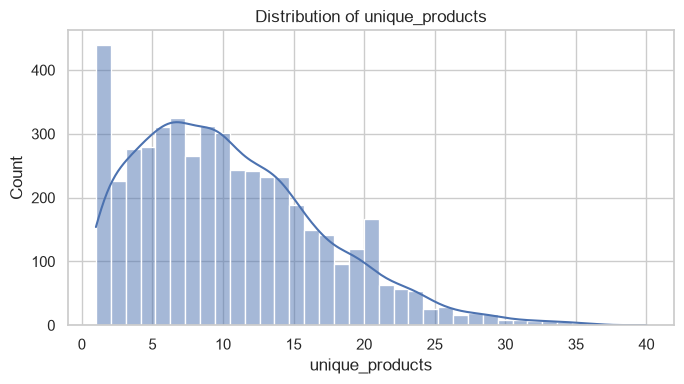

In [ ]:
# Inspect the distributions

for feature in selected_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(customer_df[feature], kde=True)
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.tight_layout()
    plt.show()

Apply `log1p` to the three most skewed features (**recency, total_sales, avg_order_value**) on a copy, so the original data stays untouched for profiling later.

In [ ]:
cluster_df = customer_df[selected_features].copy()

log_features = [
    "recency",
    "total_sales",
    "avg_order_value"
]

for feature in log_features:
    cluster_df[feature] = np.log1p(cluster_df[feature])

cluster_df.head()

,recency,total_orders,total_sales,total_profit,avg_order_value,avg_discount,unique_products
0,4.394449,5,10.128350,-1980.7393,8.519071,0.25,15
1,5.993961,5,9.854875,8981.3239,8.245647,0.12,12
2,2.833213,11,9.720526,2995.5816,7.323230,0.16,26
3,5.730100,12,9.715168,4974.5130,7.230925,0.03,30
4,4.584967,7,9.658546,2748.1878,7.713021,0.06,18


In [ ]:
cluster_df.skew().sort_values(ascending=False)

avg_discount       1.472312
total_profit       1.159391
unique_products    0.800579
total_orders       0.529275
recency           -0.438750
avg_order_value   -0.931183
total_sales       -1.120294
dtype: float64

## 3. Scaling
`StandardScaler` puts every feature on the same scale (mean 0, standard deviation 1), so no feature dominates the distance calculation just because of its units.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(cluster_df)

scaled_df = pd.DataFrame(
    scaled_features,
    columns=cluster_df.columns,
    index=cluster_df.index
)

scaled_df.head()

,recency,total_orders,total_sales,total_profit,avg_order_value,avg_discount,unique_products
0,-0.153247,-0.099696,2.138575,-3.458354,2.907042,0.786031,0.692923
1,1.029405,-0.099696,1.934412,13.155445,2.616452,-0.163770,0.232622
2,-1.307599,2.000382,1.834113,4.083620,1.636127,0.128476,2.380692
3,0.834311,2.350395,1.830113,7.082834,1.538027,-0.821325,2.994426
4,-0.012381,0.600330,1.787841,3.708677,2.050388,-0.602140,1.153223


In [ ]:
scaled_df.agg(["mean", "std"]).T

,mean,std
recency,2.566294e-16,1.000103
total_orders,9.331979e-17,1.000103
total_sales,0.000000e+00,1.000103
total_profit,4.665990e-17,1.000103
avg_order_value,-2.332995e-16,1.000103
avg_discount,-6.998984e-17,1.000103
unique_products,9.331979e-17,1.000103


## 4. Choosing the number of clusters
Two diagnostics for k = 2…10:
- **Elbow (inertia):** look for the point where adding clusters stops helping much.
- **Silhouette score:** how well separated the clusters are (higher is better).

In [ ]:
from sklearn.cluster import KMeans

inertia_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_df)

    inertia_values.append(kmeans.inertia_)

print(inertia_values)

[23353.891639572124, 19729.774761438137, 17311.292002854283, 15427.961983444304, 14240.047477310514, 13201.513440828006, 12225.004816310658, 11581.112428120912, 11066.170462067728]


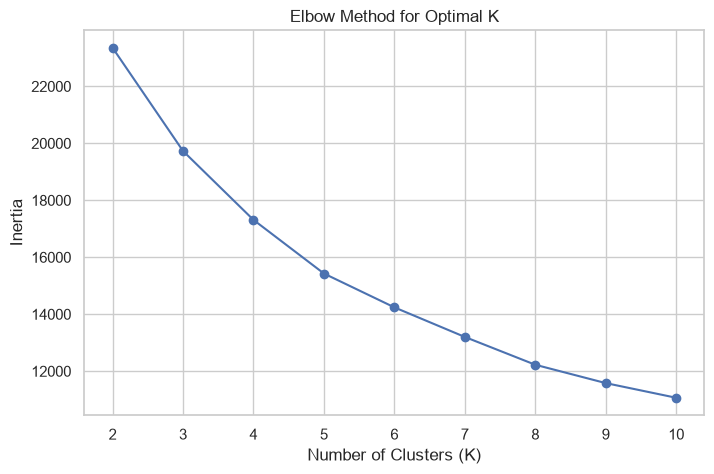

In [ ]:
#Elbow Method graph

k_values = range(2, 11)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(scaled_df)

    score = silhouette_score(scaled_df, labels)
    silhouette_values.append(score)

print(silhouette_values)

[0.2794594444065122, 0.21123191851018144, 0.2137719832890908, 0.2011198901075561, 0.1975226322747392, 0.19779071000081008, 0.19349205769614866, 0.19085057563679703, 0.19034363692324371]


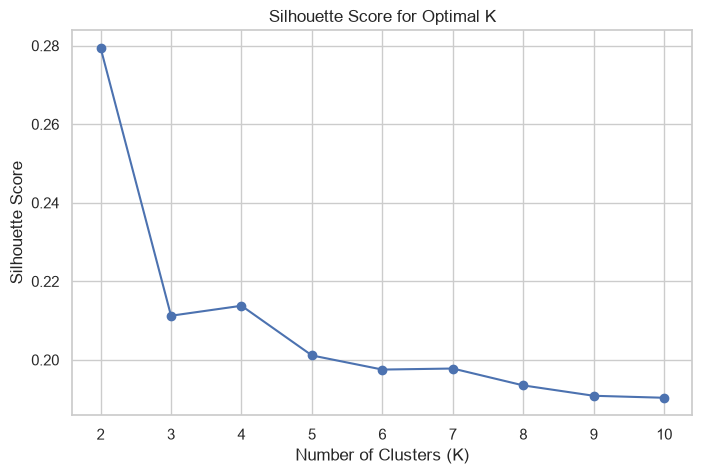

In [ ]:
k_values = range(2, 11)

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Optimal K")
plt.xticks(k_values)
plt.grid(True)
plt.show()

Cluster sizes for a few candidate values of k:

In [ ]:
#compare cluster size

for k in [2, 4, 5]:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(scaled_df)

    print(f"\nK = {k}")
    print(pd.Series(labels).value_counts().sort_index())


K = 2
0    2719
1    2154
Name: count, dtype: int64

K = 4
0     523
1    2149
2    1259
3     942
Name: count, dtype: int64

K = 5
0    1385
1     716
2     946
3     469
4    1357
Name: count, dtype: int64


**Decision:** k = 2 has the highest silhouette score (≈ 0.28). The elbow curve shows no sharp bend, so k = 2 is a coarse but stable split; k = 4 is worth exploring later if richer customer personas are needed.

## 5. Final model

In [ ]:
# Final model: k = 2 (highest silhouette score)
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

customer_df["cluster"] = final_kmeans.fit_predict(scaled_df)

customer_df["cluster"].value_counts().sort_index()

cluster
0    2719
1    2154
Name: count, dtype: int64

## 6. Cluster profiling
Profiles are computed on the **original (unscaled) values**, so they can be read in dollars, orders and days. Means show the typical level, medians show it without outlier influence.

In [ ]:
cluster_profile = customer_df.groupby("cluster")[
    selected_features
].mean().round(2)

cluster_profile

,recency,total_orders,total_sales,total_profit,avg_order_value,avg_discount,unique_products
cluster,,,,,,,
0,110.30,7.06,4043.07,530.99,612.78,0.13,14.57
1,330.03,3.04,765.92,11.00,269.88,0.16,5.33


In [ ]:
#cluster profile using median values

cluster_median = customer_df.groupby("cluster")[
    selected_features
].median().round(2)

cluster_median

,recency,total_orders,total_sales,total_profit,avg_order_value,avg_discount,unique_products
cluster,,,,,,,
0,64.0,7.0,3397.0,442.14,522.6,0.12,14.0
1,218.5,3.0,615.5,42.75,193.0,0.10,5.0


In [ ]:
# cluster sizes and percentages

cluster_summary = customer_df["cluster"].value_counts().sort_index().to_frame("customers")

cluster_summary["percentage"] = (
    cluster_summary["customers"] / len(customer_df) * 100
).round(2)

cluster_summary

,customers,percentage
cluster,,
0,2719,55.8
1,2154,44.2


**Full profile table** (size, recency, orders, sales, profit, AOV, discount, product breadth):

In [ ]:
cluster_profile_final = customer_df.groupby("cluster").agg(
    customers=("customer_id", "count"),
    avg_recency=("recency", "mean"),
    median_recency=("recency", "median"),
    avg_orders=("total_orders", "mean"),
    median_orders=("total_orders", "median"),
    avg_sales=("total_sales", "mean"),
    median_sales=("total_sales", "median"),
    avg_profit=("total_profit", "mean"),
    median_profit=("total_profit", "median"),
    avg_order_value=("avg_order_value", "mean"),
    avg_discount=("avg_discount", "mean"),
    avg_unique_products=("unique_products", "mean")
).round(2)

cluster_profile_final

,customers,avg_recency,median_recency,avg_orders,median_orders,avg_sales,median_sales,avg_profit,median_profit,avg_order_value,avg_discount,avg_unique_products
cluster,,,,,,,,,,,,
0,2719,110.30,64.0,7.06,7.0,4043.07,3397.0,530.99,442.14,612.78,0.13,14.57
1,2154,330.03,218.5,3.04,3.0,765.92,615.5,11.00,42.75,269.88,0.16,5.33


## 7. Comparison with the SQL RFM segments
Cross-tabulate the K-Means clusters against the six rule-based segments. Agreement on the extremes (Champions vs Low Engagement) is reassuring; the middle segments show where the two methods disagree.

In [ ]:
import os
from sqlalchemy import create_engine, URL

# Credentials are read from environment variables - never hard-code passwords in a repo.
db_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("PGUSER", "postgres"),
    password=os.getenv("PGPASSWORD"),
    host=os.getenv("PGHOST", "127.0.0.1"),
    port=int(os.getenv("PGPORT", 5432)),
    database=os.getenv("PGDATABASE", "superstore_project"),
)
engine = create_engine(db_url)
print("Database engine created successfully!")

Database engine created successfully!


In [ ]:
# Pull the rule-based RFM segment from SQL so we can compare it with the K-Means clusters
rfm_df = pd.read_sql(
    "SELECT customer_id, segment FROM customer_rfm_segments;",
    engine
)
customer_df = customer_df.merge(rfm_df, on="customer_id", how="left")

In [ ]:
cluster_rfm_comparison = pd.crosstab(
    customer_df["cluster"],
    customer_df["segment"]
)

cluster_rfm_comparison

segment,AT-RISK VALUABLE CUSTOMER,CHAMPIONS,LOW ENGAGEMENT CUSTOMER,LOYAL CUSTOMER,NEEDS ATTENTION,POTENTIAL LOYALIST
cluster,,,,,,
0,522,795,150,610,177,465
1,75,1,1335,6,517,220


Row percentages: what share of each cluster belongs to each RFM segment?

In [ ]:
# percentage distribution within each k means cluster

cluster_rfm_percentage = pd.crosstab(
    customer_df["cluster"],
    customer_df["segment"],
    normalize="index"
).mul(100).round(2)

cluster_rfm_percentage

segment,AT-RISK VALUABLE CUSTOMER,CHAMPIONS,LOW ENGAGEMENT CUSTOMER,LOYAL CUSTOMER,NEEDS ATTENTION,POTENTIAL LOYALIST
cluster,,,,,,
0,19.20,29.24,5.52,22.43,6.51,17.10
1,3.48,0.05,61.98,0.28,24.00,10.21


## 8. Dashboard summary

In [ ]:
dashboard_df = customer_df.copy()

dashboard_summary = dashboard_df.groupby("cluster").agg(
    customers=("customer_id", "count"),
    avg_recency=("recency", "mean"),
    avg_orders=("total_orders", "mean"),
    avg_sales=("total_sales", "mean"),
    avg_profit=("total_profit", "mean"),
    avg_discount=("avg_discount", "mean"),
    avg_products=("unique_products", "mean")
).round(2)

dashboard_summary

,customers,avg_recency,avg_orders,avg_sales,avg_profit,avg_discount,avg_products
cluster,,,,,,,
0,2719,110.30,7.06,4043.07,530.99,0.13,14.57
1,2154,330.03,3.04,765.92,11.00,0.16,5.33


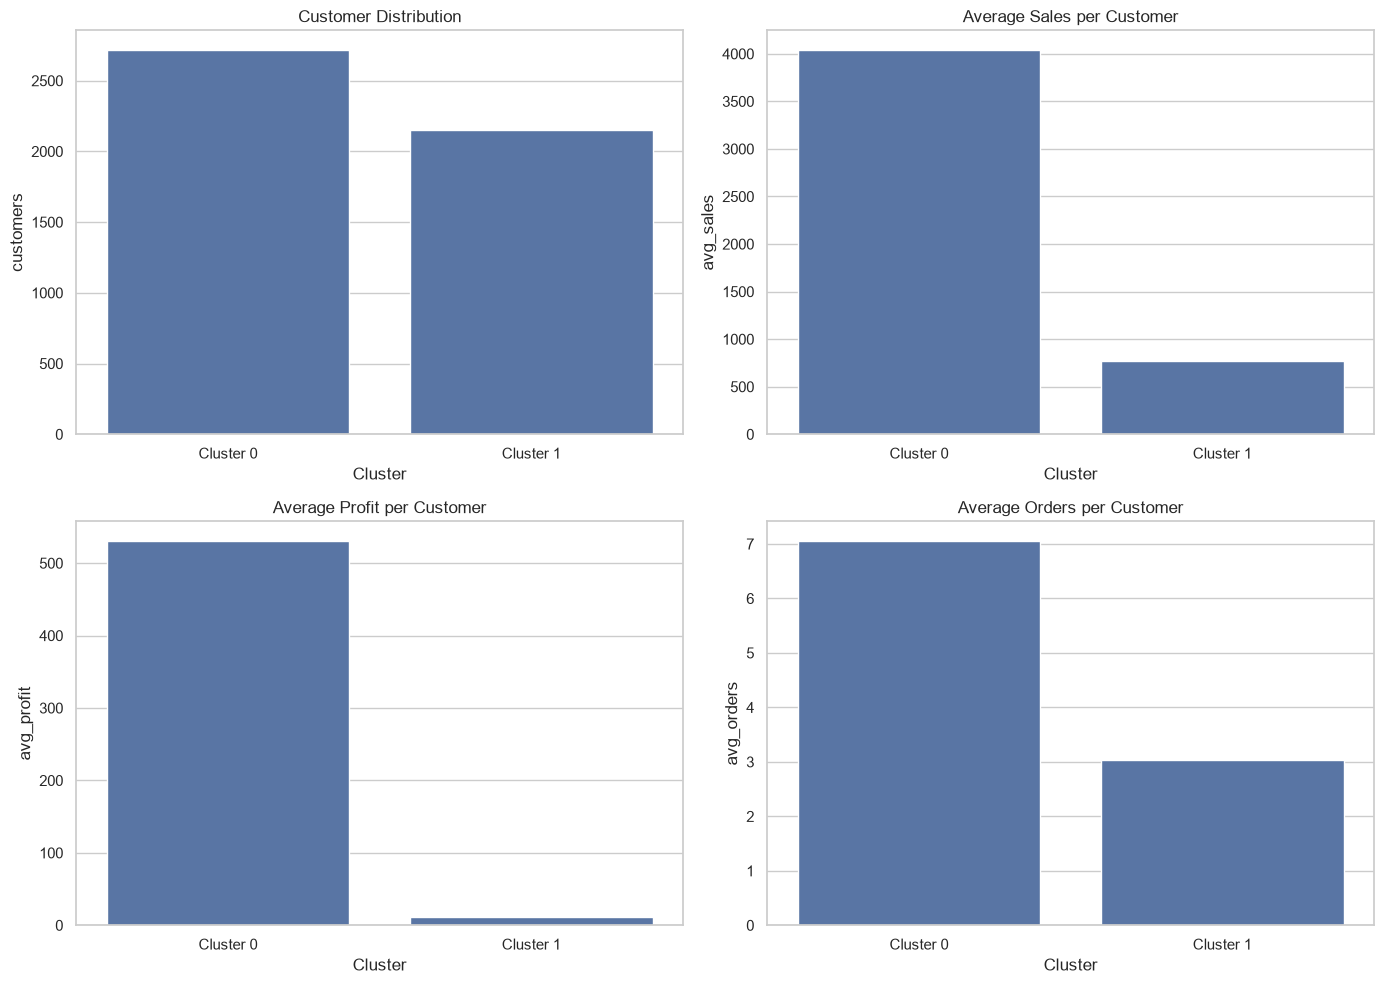

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.barplot(data=dashboard_summary, x=dashboard_summary.index,
            y="customers", ax=axes[0, 0])
axes[0, 0].set_title("Customer Distribution")

sns.barplot(data=dashboard_summary, x=dashboard_summary.index,
            y="avg_sales", ax=axes[0, 1])
axes[0, 1].set_title("Average Sales per Customer")

sns.barplot(data=dashboard_summary, x=dashboard_summary.index,
            y="avg_profit", ax=axes[1, 0])
axes[1, 0].set_title("Average Profit per Customer")

sns.barplot(data=dashboard_summary, x=dashboard_summary.index,
            y="avg_orders", ax=axes[1, 1])
axes[1, 1].set_title("Average Orders per Customer")

for ax in axes.flat:
    ax.set_xlabel("Cluster")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Cluster 0", "Cluster 1"])

plt.tight_layout()
plt.show()

## Conclusions
- **Two clear groups:** an active, high-value cluster (about 56% of customers) and a lapsed, low-value cluster (about 44%) whose average profit is close to zero.
- **The methods agree on the extremes:** almost all *Champions* sit in the active cluster, and most *Low Engagement* customers sit in the lapsed one.
- **Limitations:** k = 2 is a coarse split; clusters are descriptive, not predictions of future behavior.